# Multiclass Classification

Our dataset consists of clinical data from patients who entered the hospital complaining of chest pain ("angina") during exercise.  The information collected includes:

* `age` : Age of the patient

* `sex` : Sex of the patient

* `cp` : Chest Pain type

    + Value 0: asymptomatic
    + Value 1: typical angina
    + Value 2: atypical angina
    + Value 3: non-anginal pain
   
    
* `trtbps` : resting blood pressure (in mm Hg)

* `chol` : cholesterol in mg/dl fetched via BMI sensor

* `restecg` : resting electrocardiographic results

    + Value 0: normal
    + Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
    + Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria

* `thalach` : maximum heart rate achieved during exercise

* `output` : the doctor's diagnosis of whether the patient is at risk for a heart attack
    + 0 = not at risk of heart attack
    + 1 = at risk of heart attack

In [1]:
## library imports here
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from plotnine import *

First we'll create binary variables for each class.

In [2]:
ha = pd.read_csv("https://www.dropbox.com/s/aohbr6yb9ifmc8w/heart_attack.csv?dl=1")

ha["cp_is_3"] = ((ha["cp"] == 3) * 1)
ha["cp_is_2"] = ((ha["cp"] == 2) * 1)
ha["cp_is_1"] = ((ha["cp"] == 1) * 1)
ha["cp_is_0"] = ((ha["cp"] == 0) * 1)

# strings for the purposes of plotting
ha["cp"] = ha["cp"].astype("str")
ha

,age,sex,cp,trtbps,chol,restecg,thalach,output,cp_is_3,cp_is_2,cp_is_1,cp_is_0
0,63,1,3,145,233,0,150,1,1,0,0,0
1,37,1,2,130,250,1,187,1,0,1,0,0
2,56,1,1,120,236,1,178,1,0,0,1,0
3,57,0,0,120,354,1,163,1,0,0,0,1
4,57,1,0,140,192,1,148,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
268,59,1,0,164,176,0,90,0,0,0,0,1
269,57,0,0,140,241,1,123,0,0,0,0,1
270,45,1,3,110,264,1,132,0,1,0,0,0
271,68,1,0,144,193,1,141,0,0,0,0,1


The target is `cp` which has 4 categories. How common is each category?

In [3]:
ha["cp"].value_counts().sort_index()

cp
0    128
1     44
2     81
3     20
Name: count, dtype: int64

Let's consider as predictors: `trtbps`, `chol`, `age`.

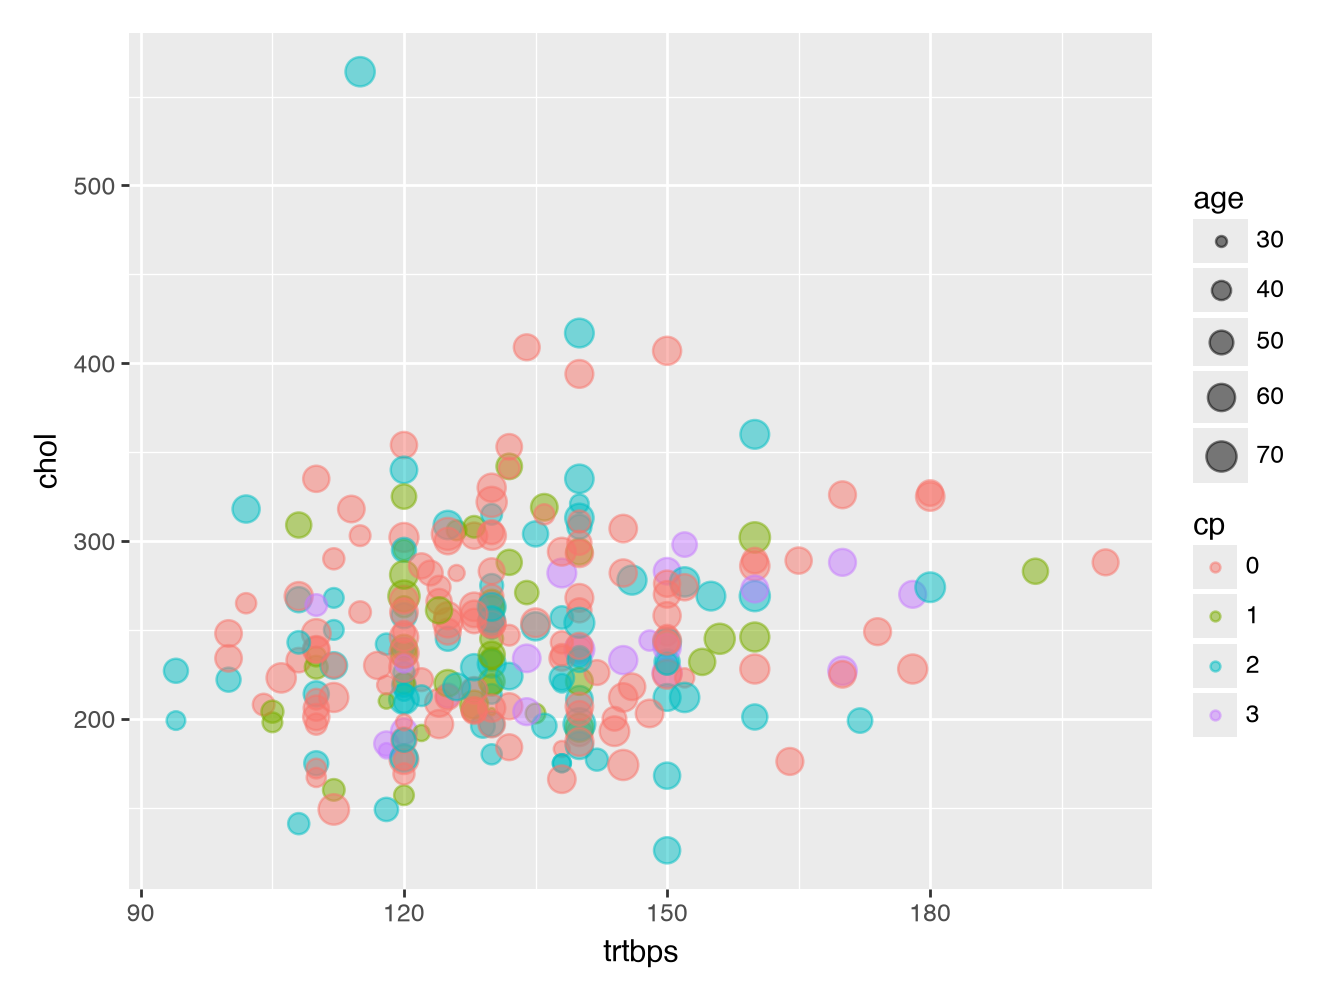

In [4]:
(ggplot(ha, aes(x="trtbps", y="chol", size = "age", color="cp"))
+ geom_point(alpha = 0.5))

## Q1: A Natural Multiclass Model: k-nearest neighbors

Fit a multiclass 10-nearest neighbors model. Output the predicted class probabilities and plot the predicted classes for the training data. Estimate the test:

- accuracy
- macro precision, recall, and F1 scores
- precision, recall, and F1 score for each class. You will likely get some weird values; can you explain why?


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from IPython.display import display

In [6]:
X = ha[["trtbps", "chol", "age"]]
y = ha["cp"]

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=10)
)

knn_model.fit(X, y)

# Training-data probabilities and predicted classes
probability_columns = [
    f"knn_prob_cp_{category}"
    for category in knn_model.classes_
]

ha[probability_columns] = knn_model.predict_proba(X)
ha["knn_predicted_cp"] = knn_model.predict(X)

display(
    ha[probability_columns + ["knn_predicted_cp"]].head(10)
)

,knn_prob_cp_0,knn_prob_cp_1,knn_prob_cp_2,knn_prob_cp_3,knn_predicted_cp
0,0.5,0.1,0.1,0.3,0
1,0.2,0.1,0.6,0.1,2
2,0.2,0.5,0.3,0.0,1
3,0.7,0.2,0.1,0.0,0
4,0.6,0.1,0.2,0.1,0
5,0.4,0.3,0.2,0.1,0
6,0.3,0.2,0.4,0.1,2
7,0.3,0.1,0.5,0.1,2
8,0.5,0.0,0.5,0.0,0
9,0.5,0.2,0.3,0.0,0


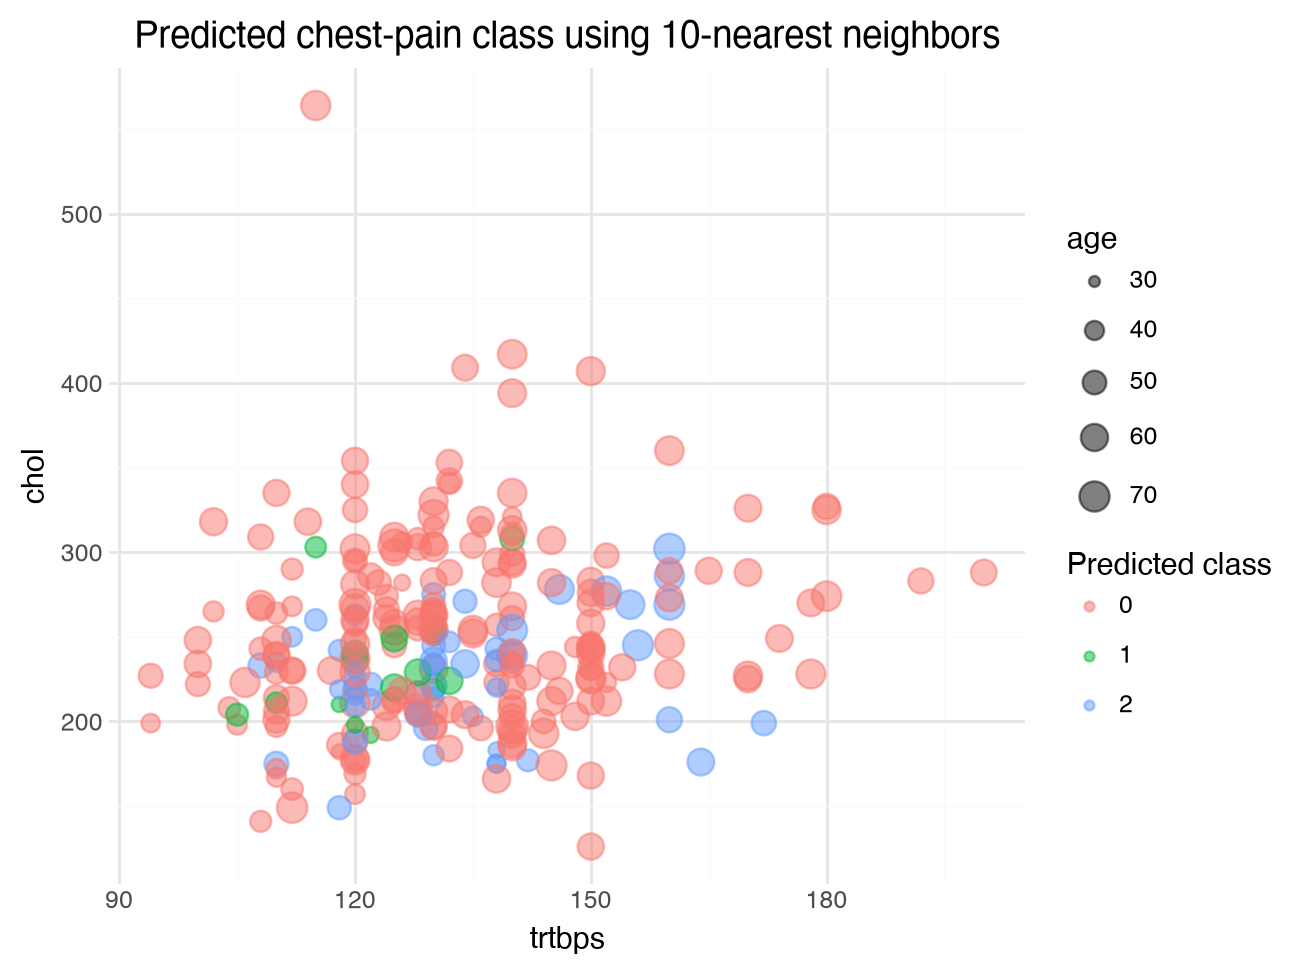

In [7]:
(
    ggplot(
        ha,
        aes(
            x="trtbps",
            y="chol",
            size="age",
            color="knn_predicted_cp"
        )
    )
    + geom_point(alpha=0.5)
    + labs(
        title="Predicted chest-pain class using 10-nearest neighbors",
        color="Predicted class"
    )
    + theme_minimal()
)

In [8]:
knn_cv_predictions = cross_val_predict(
    knn_model,
    X,
    y,
    cv=10
)

print(
    "Cross-validated accuracy:",
    accuracy_score(y, knn_cv_predictions)
)

print(
    classification_report(
        y,
        knn_cv_predictions,
        digits=3,
        zero_division=0
    )
)

Cross-validated accuracy: 0.4432234432234432
              precision    recall  f1-score   support

           0      0.481     0.797     0.600       128
           1      0.400     0.091     0.148        44
           2      0.306     0.185     0.231        81
           3      0.000     0.000     0.000        20

    accuracy                          0.443       273
   macro avg      0.297     0.268     0.245       273
weighted avg      0.381     0.443     0.374       273



## Q2:  OvR for Class 3



Fit a logistic regression model for predicting Class 3. Output the predicted class probabilities (Class 3 or not) and plot the predicted classes (Class 3 or not) for the training data. Estimate the test:

- precision, recall, and F1 score for class 3

In [9]:
X = ha[["trtbps", "chol", "age"]]
y_class_3 = ha["cp_is_3"]

ovr_3_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

ovr_3_model.fit(X, y_class_3)

# Training-data probabilities and predictions
ha[["prob_not_3", "prob_class_3"]] = (
    ovr_3_model.predict_proba(X)
)

ha["predicted_class_3"] = ovr_3_model.predict(X)

ha["predicted_3_label"] = ha["predicted_class_3"].map({
    0: "Not Class 3",
    1: "Class 3"
})

display(
    ha[
        [
            "prob_not_3",
            "prob_class_3",
            "predicted_3_label"
        ]
    ].head(10)
)

,prob_not_3,prob_class_3,predicted_3_label
0,0.901104,0.098896,Not Class 3
1,0.941224,0.058776,Not Class 3
2,0.951037,0.048963,Not Class 3
3,0.971022,0.028978,Not Class 3
4,0.898105,0.101895,Not Class 3
5,0.934077,0.065923,Not Class 3
6,0.957437,0.042563,Not Class 3
7,0.782937,0.217063,Not Class 3
8,0.854818,0.145182,Not Class 3
9,0.916802,0.083198,Not Class 3


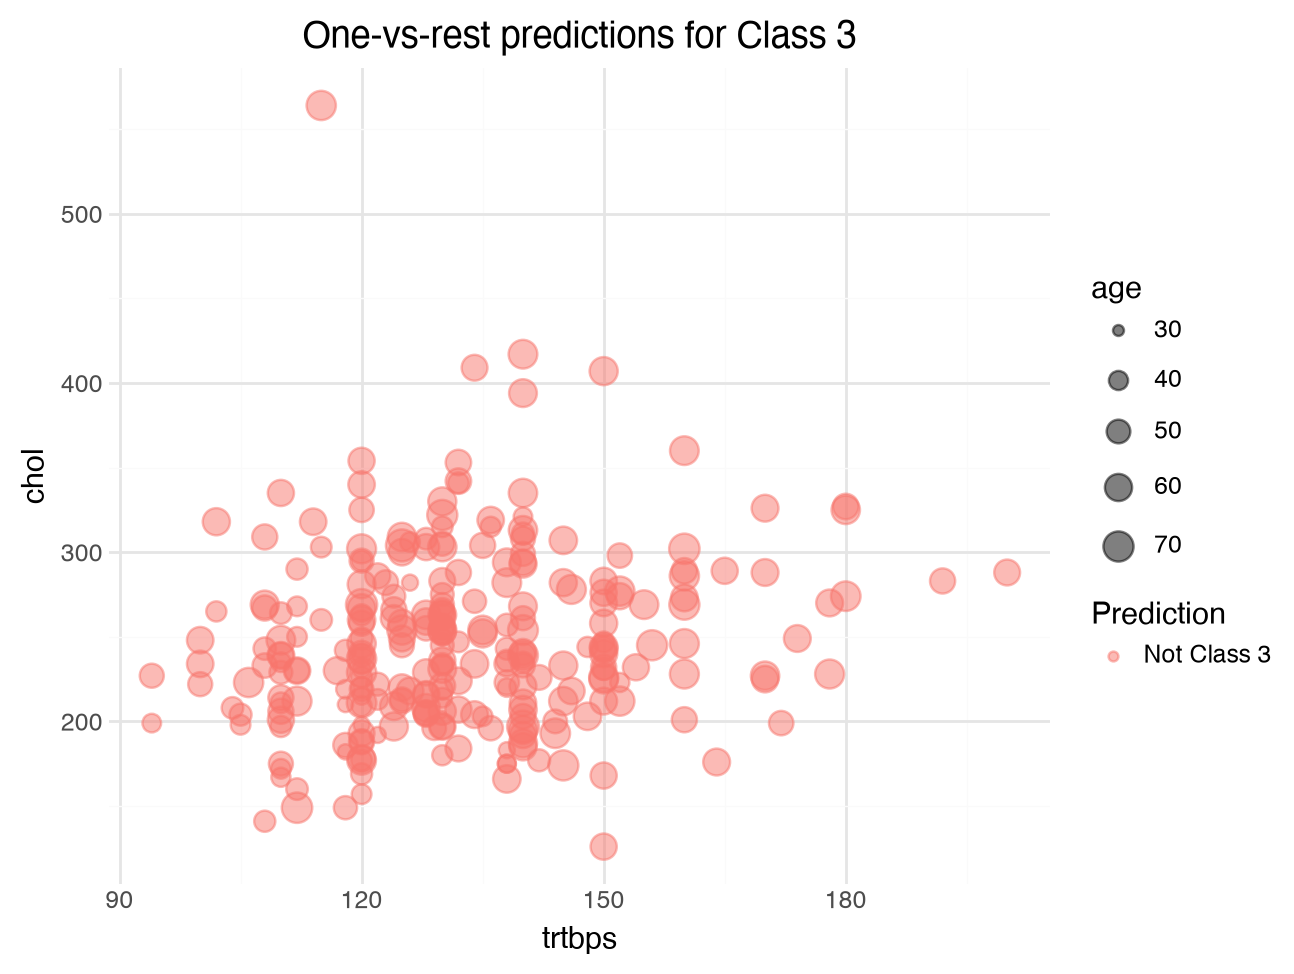

In [10]:
(
    ggplot(
        ha,
        aes(
            x="trtbps",
            y="chol",
            size="age",
            color="predicted_3_label"
        )
    )
    + geom_point(alpha=0.5)
    + labs(
        title="One-vs-rest predictions for Class 3",
        color="Prediction"
    )
    + theme_minimal()
)

In [11]:
cv_predictions_3 = cross_val_predict(
    ovr_3_model,
    X,
    y_class_3,
    cv=10
)

q2_precision = precision_score(
    y_class_3,
    cv_predictions_3,
    zero_division=0
)

q2_recall = recall_score(
    y_class_3,
    cv_predictions_3,
    zero_division=0
)

q2_f1 = f1_score(
    y_class_3,
    cv_predictions_3,
    zero_division=0
)

pd.Series({
    "Precision": q2_precision,
    "Recall": q2_recall,
    "F1 score": q2_f1
})

Precision    0.0
Recall       0.0
F1 score     0.0
dtype: float64

## Q3: OvR - Other classes.

Repeat Q2 for each of the other three `cp` categories.  Which category was the OvR approach best at distinguishing?

,prob_not_0,prob_class_0,predicted_0_label
0,0.478092,0.521908,Class 0
1,0.678292,0.321708,Not Class 0
2,0.504099,0.495901,Not Class 0
3,0.443054,0.556946,Class 0
4,0.543651,0.456349,Not Class 0
5,0.507843,0.492157,Not Class 0
6,0.600599,0.399401,Not Class 0
7,0.630345,0.369655,Not Class 0
8,0.568618,0.431382,Not Class 0
9,0.550279,0.449721,Not Class 0


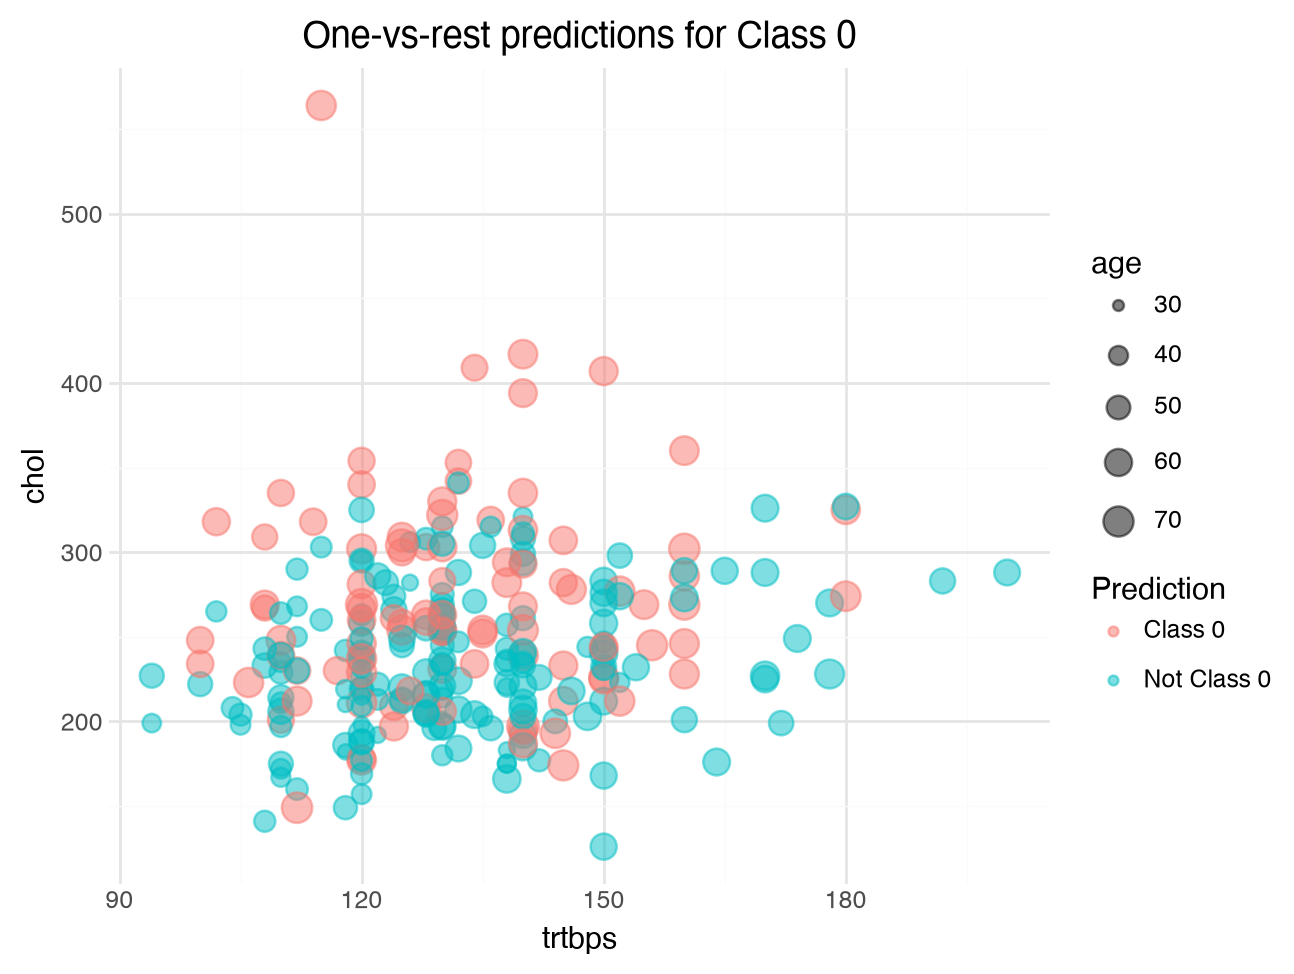

,prob_not_1,prob_class_1,predicted_1_label
0,0.894867,0.105133,Not Class 1
1,0.734949,0.265051,Not Class 1
2,0.845941,0.154059,Not Class 1
3,0.820938,0.179062,Not Class 1
4,0.876054,0.123946,Not Class 1
5,0.849236,0.150764,Not Class 1
6,0.767814,0.232186,Not Class 1
7,0.877052,0.122948,Not Class 1
8,0.887602,0.112398,Not Class 1
9,0.852491,0.147509,Not Class 1


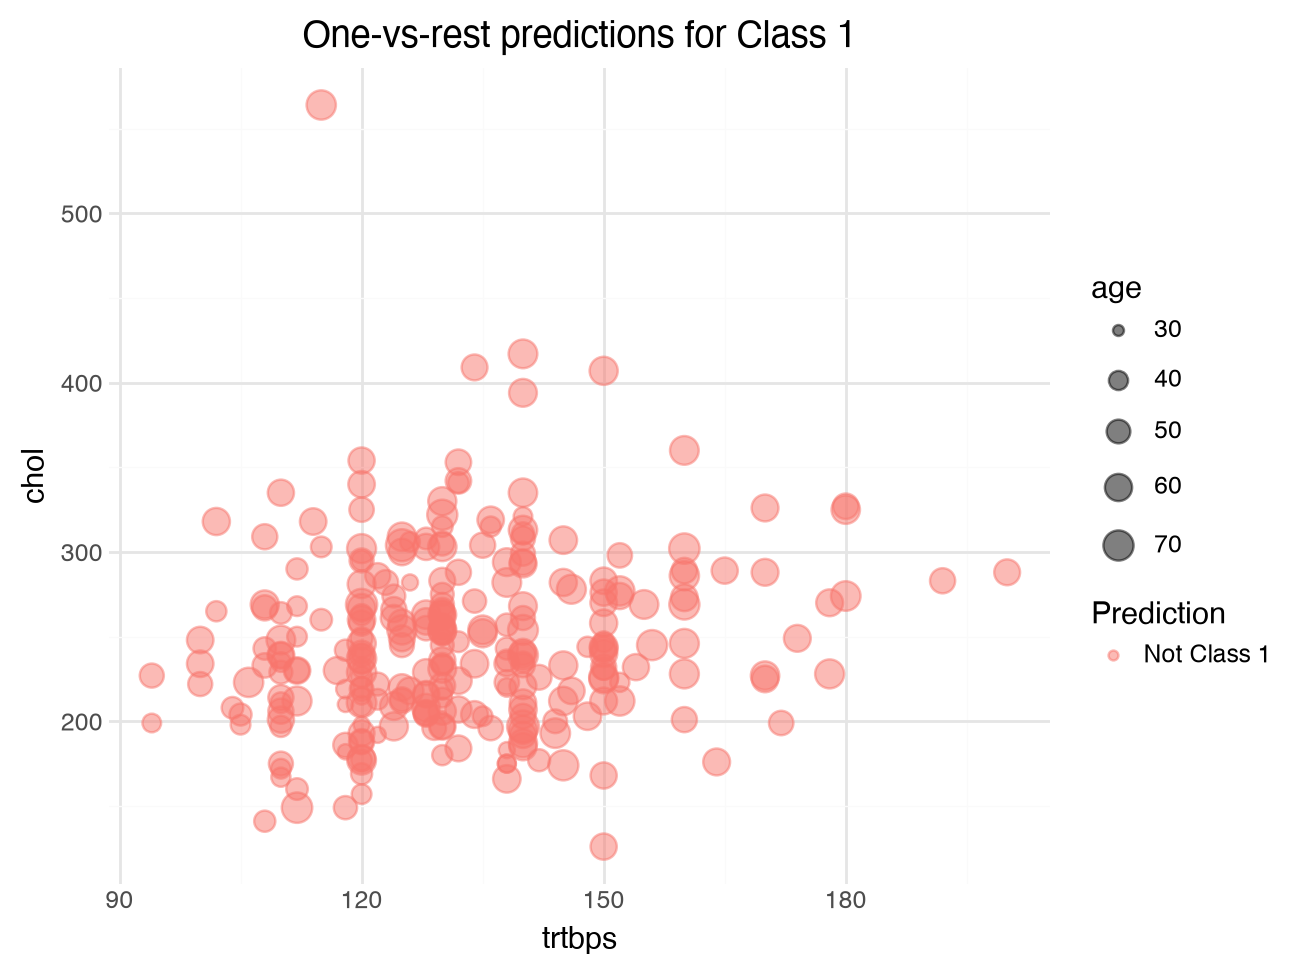

,prob_not_2,prob_class_2,predicted_2_label
0,0.731442,0.268558,Not Class 2
1,0.638588,0.361412,Not Class 2
2,0.706497,0.293503,Not Class 2
3,0.753821,0.246179,Not Class 2
4,0.693586,0.306414,Not Class 2
5,0.729453,0.270547,Not Class 2
6,0.671777,0.328223,Not Class 2
7,0.678633,0.321367,Not Class 2
8,0.684284,0.315716,Not Class 2
9,0.701075,0.298925,Not Class 2


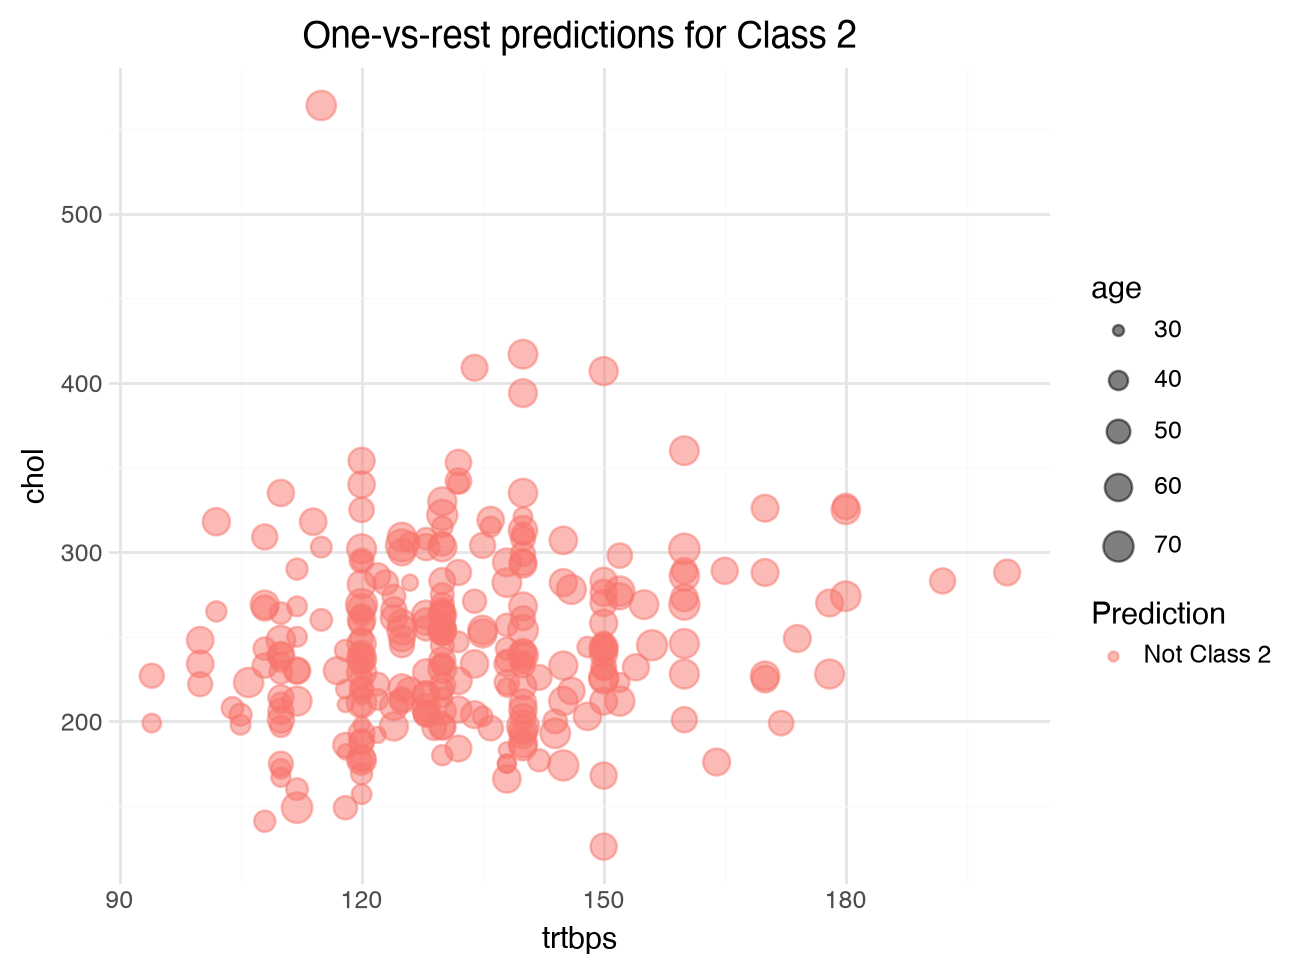

In [12]:
other_ovr_results = []

for category in ["0", "1", "2"]:

    y_binary = ha[f"cp_is_{category}"]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    model.fit(X, y_binary)

    # Training probabilities and predictions
    ha[
        [
            f"prob_not_{category}",
            f"prob_class_{category}"
        ]
    ] = model.predict_proba(X)

    ha[f"predicted_class_{category}"] = model.predict(X)

    label_column = f"predicted_{category}_label"

    ha[label_column] = ha[
        f"predicted_class_{category}"
    ].map({
        0: f"Not Class {category}",
        1: f"Class {category}"
    })

    display(
        ha[
            [
                f"prob_not_{category}",
                f"prob_class_{category}",
                label_column
            ]
        ].head(10)
    )

    plot = (
        ggplot(
            ha,
            aes(
                x="trtbps",
                y="chol",
                size="age",
                color=label_column
            )
        )
        + geom_point(alpha=0.5)
        + labs(
            title=f"One-vs-rest predictions for Class {category}",
            color="Prediction"
        )
        + theme_minimal()
    )

    display(plot)

    cv_predictions = cross_val_predict(
        model,
        X,
        y_binary,
        cv=10
    )

    other_ovr_results.append({
        "class": category,
        "precision": precision_score(
            y_binary,
            cv_predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_binary,
            cv_predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_binary,
            cv_predictions,
            zero_division=0
        )
    })

In [13]:
ovr_results = pd.DataFrame(
    [
        {
            "class": "3",
            "precision": q2_precision,
            "recall": q2_recall,
            "f1": q2_f1
        }
    ]
    + other_ovr_results
)

display(ovr_results.sort_values("f1", ascending=False))

best_class = ovr_results.loc[
    ovr_results["f1"].idxmax(),
    "class"
]

print("Best distinguished category:", best_class)

,class,precision,recall,f1
1,0,0.536082,0.40625,0.462222
0,3,0.000000,0.00000,0.000000
2,1,0.000000,0.00000,0.000000
3,2,0.000000,0.00000,0.000000


Best distinguished category: 0


## Q4: OvO

Reduce your dataset to only the `0` and `1` types of chest pain.

Then, fit a Logistic Regression to predict between the two groups, and estimate the ROC-AUC.  


In [14]:
pair_01 = ha[
    ha["cp"].isin(["0", "1"])
].copy()

X_01 = pair_01[["trtbps", "chol", "age"]]

# 1 means Class 1; 0 means Class 0
y_01 = (pair_01["cp"] == "1").astype(int)

ovo_01_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

ovo_01_model.fit(X_01, y_01)

# Out-of-fold probability of Class 1
cv_probability_01 = cross_val_predict(
    ovo_01_model,
    X_01,
    y_01,
    cv=10,
    method="predict_proba"
)[:, 1]

auc_01 = roc_auc_score(
    y_01,
    cv_probability_01
)

print("ROC-AUC for Class 0 versus Class 1:", auc_01)

ROC-AUC for Class 0 versus Class 1: 0.6015625


## Q5: OvO

Repeat Q4 comparing category `0` to `2`, and again to compare category `0` to `3`.  Which pair was the OvO approach best at distinguishing?

In [15]:
ovo_results = [
    {
        "comparison": "0 vs 1",
        "roc_auc": auc_01
    }
]

for other_class in ["2", "3"]:

    pair = ha[
        ha["cp"].isin(["0", other_class])
    ].copy()

    X_pair = pair[["trtbps", "chol", "age"]]

    # 1 means the other class; 0 means Class 0
    y_pair = (
        pair["cp"] == other_class
    ).astype(int)

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    model.fit(X_pair, y_pair)

    cv_probability = cross_val_predict(
        model,
        X_pair,
        y_pair,
        cv=10,
        method="predict_proba"
    )[:, 1]

    pair_auc = roc_auc_score(
        y_pair,
        cv_probability
    )

    ovo_results.append({
        "comparison": f"0 vs {other_class}",
        "roc_auc": pair_auc
    })

ovo_results = pd.DataFrame(ovo_results)

display(
    ovo_results.sort_values(
        "roc_auc",
        ascending=False
    )
)

best_pair = ovo_results.loc[
    ovo_results["roc_auc"].idxmax(),
    "comparison"
]

print("Best distinguished pair:", best_pair)

,comparison,roc_auc
0,0 vs 1,0.601562
2,0 vs 3,0.590234
1,0 vs 2,0.559606


Best distinguished pair: 0 vs 1
